<a href="https://colab.research.google.com/github/pauloricardopg/RedesNeuraisArtificiais-PPCOM/blob/main/Classificar_o_MNIST_original.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [42]:
import numpy as np
from scipy.io import loadmat
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

# 2. Configuração do dispositivo
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo utilizado: {device}")

# 3. Carregamento dos dados a partir do ficheiro .mat original
mnist = loadmat("/content/mnist-original.mat") # ou .loadmat
mnist_data = mnist["data"].T
mnist_label = mnist["label"][0]

# 4. Divisão em Treino e Teste (padrão do MNIST)
train_images, test_images = mnist_data[:60000], mnist_data[60000:]
train_labels, test_labels = mnist_label[:60000], mnist_label[60000:]

print(f"Imagens de treino: {train_images.shape}")
print(f"Imagens de teste: {test_images.shape}")

Dispositivo utilizado: cpu
Imagens de treino: (60000, 784)
Imagens de teste: (10000, 784)


In [43]:
class TorchCNN2D(nn.Module):
    def __init__(self, input_shape, num_classes):
        super(TorchCNN2D, self).__init__()
        # input_shape[0] corresponde aos canais da imagem (1 para escala de cinzentos)
        self.conv1 = nn.Conv2d(in_channels=input_shape[0], out_channels=32, kernel_size=3)
        self.pool1 = nn.MaxPool2d(kernel_size=2)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3)
        self.pool2 = nn.MaxPool2d(kernel_size=2)
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(in_features=1152, out_features=num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool1(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool2(x)
        x = self.conv3(x)
        x = F.relu(x)
        x = self.flatten(x)
        x = self.fc1(x)
        return x

In [44]:
# Classe que envolve a rede PyTorch para funcionar numa Pipeline do Scikit-Learn
class TorchWrappedNN(BaseEstimator, ClassifierMixin):
    def __init__(self, epochs, batch_size, model_fabric=TorchCNN2D):
        self.epochs = epochs
        self.batch_size = batch_size
        self.model_fabric = model_fabric

    def fit(self, X, y):
        self.labels, ids = np.unique(y, return_inverse=True)

        # Conversão de matrizes NumPy para tensores do PyTorch e envio para o dispositivo
        X_tensor = torch.from_numpy(X).float().to(device)
        y_tensor = torch.from_numpy(y).long().to(device)

        dataset = TensorDataset(X_tensor, y_tensor)
        loader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model = self.model_fabric(input_shape=X.shape[1:], num_classes=len(self.labels)).to(device)
        self.optimizer = optim.Adam(self.model.parameters(), lr=0.001)
        self.criterion = nn.CrossEntropyLoss()

        # Ciclo de treino
        for epoch in range(self.epochs):
            for batch_idx, (images, labels) in enumerate(loader):
                self.optimizer.zero_grad()
                outputs = self.model(images)
                loss = self.criterion(outputs, labels)
                loss.backward()
                self.optimizer.step()
            print(f"Epoch {epoch+1}/{self.epochs}, Loss: {loss.item():.4f}")

        return self

    def predict(self, X):
        with torch.no_grad():
            X_tensor = torch.tensor(X, dtype=torch.float32).to(device)
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs.data, 1)
            return self.labels[predicted.cpu().numpy()]

In [45]:
class Divide255(TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        return X / 255.0

class Shape2Torch(TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        return X.reshape((X.shape[0], 1, 28, 28))

In [46]:
# Construção e execução da Pipeline com o modelo em PyTorch
model_pipeline = Pipeline([
    ('scaler', Divide255()),
    ('flatten', Shape2Torch()),
    ('nn', TorchWrappedNN(epochs=5, batch_size=128))
])

print("A iniciar o treino do modelo CNN em PyTorch...")
model_pipeline.fit(train_images, train_labels)

print("A gerar as previsões e a avaliar o modelo...")
y_pred = model_pipeline.predict(test_images)

# Apresentação do resultado
print(f"Acurácia final no Teste: {accuracy_score(test_labels, y_pred):.4f}")

A iniciar o treino do modelo CNN em PyTorch...
Epoch 1/5, Loss: 0.1695
Epoch 2/5, Loss: 0.0225
Epoch 3/5, Loss: 0.0350
Epoch 4/5, Loss: 0.0637
Epoch 5/5, Loss: 0.0422
A gerar as previsões e a avaliar o modelo...
Acurácia final no Teste: 0.9903


/usr/local/lib/python3.13/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


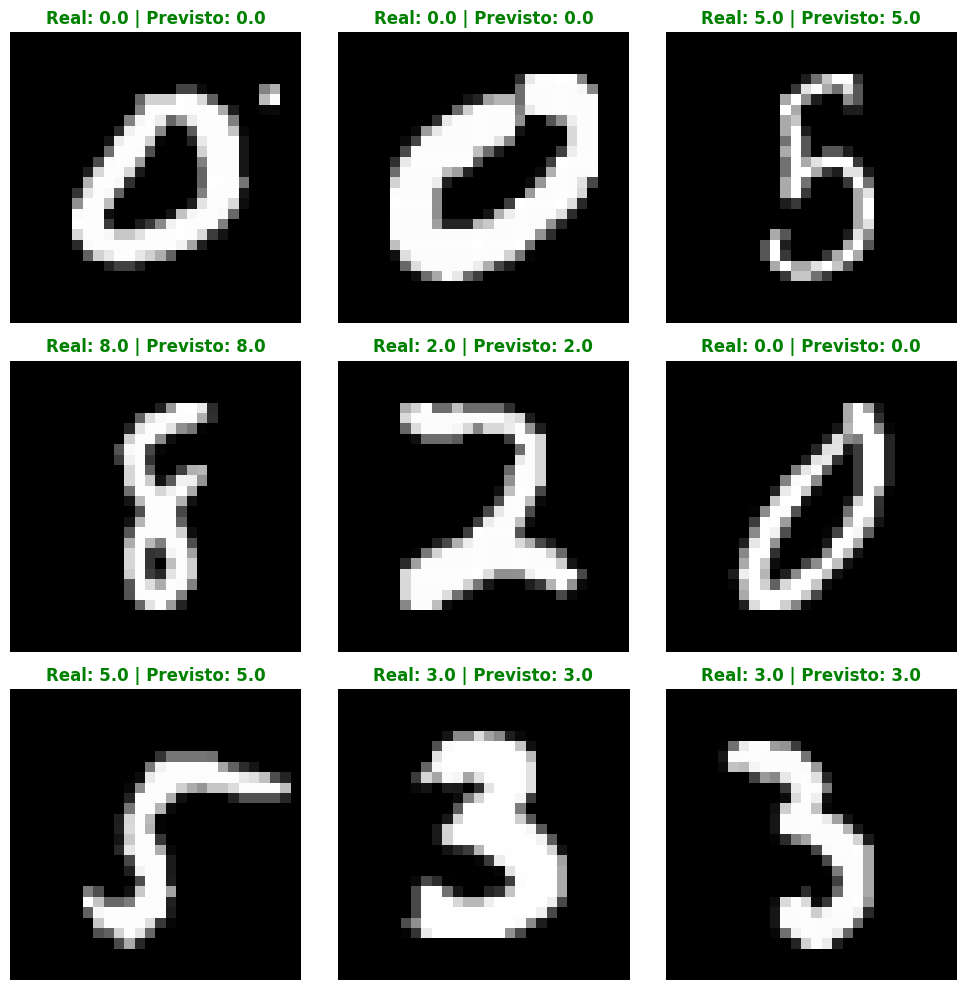

In [49]:
# 1. Escolher 9 índices aleatórios do conjunto de teste
num_samples = 9
random_indices = np.random.choice(len(test_images), num_samples, replace=False)

# 2. Configurar a figura para exibir uma grelha 3x3
plt.figure(figsize=(10, 10))

for i, idx in enumerate(random_indices):
    # A imagem original está achatada (784,), precisamos de a redimensionar para 28x28 para exibir
    image = test_images[idx].reshape(28, 28)
    true_label = test_labels[idx]
    pred_label = y_pred[idx]

    plt.subplot(3, 3, i + 1)
    plt.imshow(image, cmap='gray')
    plt.axis('off')

    # 3. Definir a cor do texto (Verde = Acerto, Vermelho = Erro)
    color = 'green' if true_label == pred_label else 'red'
    plt.title(f"Real: {true_label} | Previsto: {pred_label}", color=color, fontweight='bold')

plt.tight_layout()
plt.show()

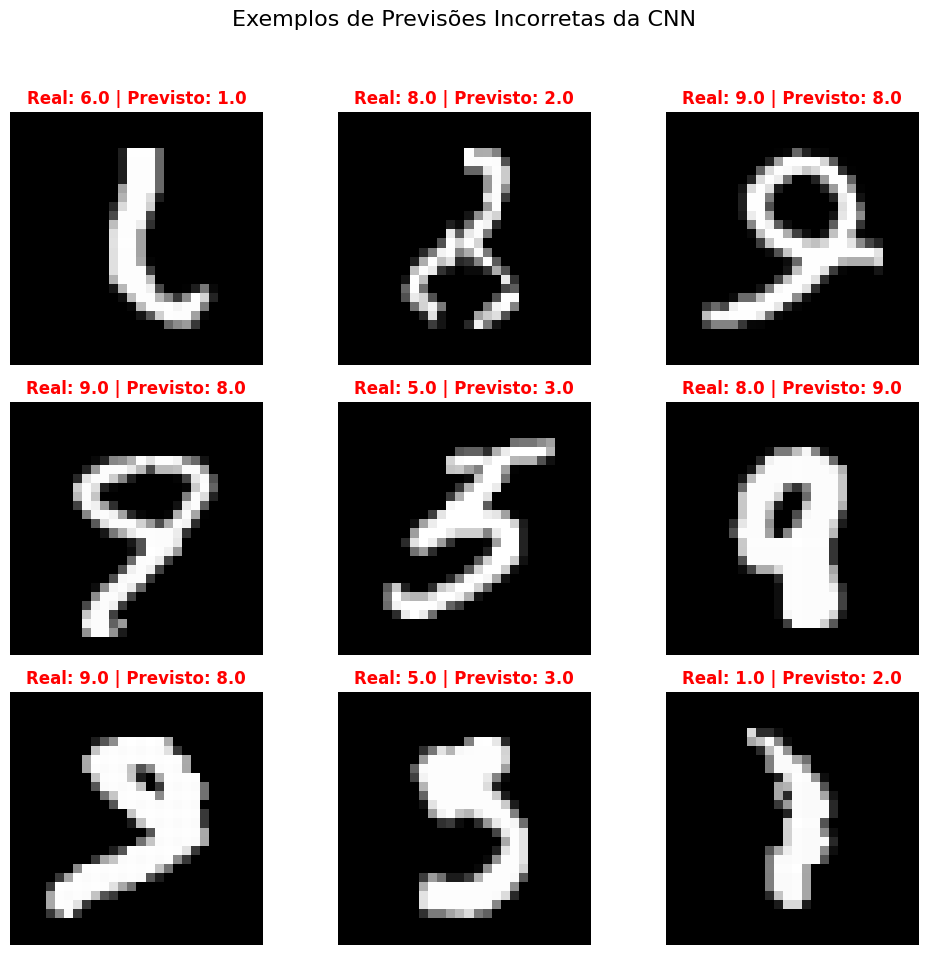

In [50]:
# 1. Encontrar os índices onde o modelo errou
incorrect_indices = np.where(y_pred != test_labels)[0]

# 2. Selecionar até 9 erros para visualizar
num_errors = min(9, len(incorrect_indices))
selected_errors = np.random.choice(incorrect_indices, num_errors, replace=False)

plt.figure(figsize=(10, 10))
plt.suptitle("Exemplos de Previsões Incorretas da CNN", fontsize=16)

for i, idx in enumerate(selected_errors):
    image = test_images[idx].reshape(28, 28)
    true_label = test_labels[idx]
    pred_label = y_pred[idx]

    plt.subplot(3, 3, i + 1)
    plt.imshow(image, cmap='gray')
    plt.axis('off')
    plt.title(f"Real: {true_label} | Previsto: {pred_label}", color='red', fontweight='bold')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()